# Probability


**Probability** is a way to measure how likely something is to happen. It is a number between 0 and 1:

| Probability | Meaning | Example |
|---|---|---|
| 0 | Impossible | Rolling a 7 on a normal dice |
| 0.5 | Equal chance | Getting Heads in a coin toss |
| 1 | Certain | The sun rising tomorrow |

- **sample space:** all possible outcomes. For a dice: `{1, 2, 3, 4, 5, 6}`
- **Event:** any group of outcomes we care about, example: "dice shows an even number" = `{2, 4, 6}`
- We write P(E) to mean "the probability of event E".
- When all outcomes are equally likely:
  > **P(E) = (number of outcomes in the event) ÷ (total number of outcomes)**

In [23]:
# Import files
import math
import random
from collections import Counter
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [24]:
# Simple probability with a dice
dice = [1, 2, 3, 4, 5, 6]                 # the universe
even = [x for x in dice if x % 2 == 0]    # the event "even number"

p_even = len(even) / len(dice)
print("Even outcomes:", even)
print("P(even) =", p_even)

Even outcomes: [2, 4, 6]
P(even) = 0.5


## Dependence and Independence

Two events are:
- **Independent** → knowing that one happened tells you nothing about the other.
- **Dependent** → knowing that one happened changes the chance of the other.

| Events | Type | Why |
|---|---|---|
| Toss 1 is Heads, Toss 2 is Heads | Independent | The coin has no memory |
| Toss 1 is Heads, **Both** tosses are Tails | Dependent | If toss 1 is Heads, "both Tails" becomes impossible |
| It rains today, You carry an umbrella | Dependent | Rain changes your chance of carrying one |

### The rule for independent events
If E and F are independent, the chance that both happen:
       
        P(E and F) = P(E) × P(F)


In [25]:
# Filping of coins with 100000 trials
random.seed(42)

def toss():
    return random.choice(["H", "T"])

trials = 100000
first_heads = 0
both_heads = 0
first_heads_and_both_tails = 0

for _ in range(trials):
    t1, t2 = toss(), toss()
    if t1 == "H":
        first_heads += 1
    if t1 == "H" and t2 == "H":
        both_heads += 1
    both_tails = (t1 == "T" and t2 == "T")
    if t1 == "H" and both_tails:
        first_heads_and_both_tails += 1

print("P(toss 1 = H) =", first_heads / trials)         
print("P(both H) =", both_heads / trials)           
print("P(toss 1 = H, both T) =", first_heads_and_both_tails / trials,
      " → not 0.5 × 0.25, so these are DEPENDENT")

P(toss 1 = H) = 0.50025
P(both H) = 0.25116
P(toss 1 = H, both T) = 0.0  → not 0.5 × 0.25, so these are DEPENDENT


## Conditional Probability

**Conditional probability** means: *"What is the chance of E, given that we already know F has happened?"*

We write it as **P(E | F)** (read: "probability of E given F").

> **P(E | F) = P(E and F) ÷ P(F)**

- If E and F are **independent**, then P(E | F) = P(E). Knowing F changes nothing.
- If they are **dependent**, knowing F changes the answer.

In [26]:
# Boys and Girls like Cricket and not like criket. 
# Find the probability of the girls students like cricket.
boys_cric = 20 
boys_no = 5
girls_cric = 10
girls_no = 15
total = boys_cric + boys_no + girls_cric + girls_no

p_cric = (boys_cric + girls_cric) / total
p_girl = (girls_cric + girls_no) / total
p_cric_girl = girls_cric / total

print("P(cricket) =", p_cric)
print("P(girl) =", p_girl)
print("P(cricket | girl) =", p_cric_girl / p_girl)  

P(cricket) = 0.6
P(girl) = 0.5
P(cricket | girl) = 0.4


## Bayes's Theorem

**Bayes's Theorem** helps us "reverse" a conditional probability.

- Often we know P(F | E) but we actually want P(E | F). Bayes's Theorem connects them:
> **P(E | F) = P(F | E) × P(E) ÷ P(F)**
    
- splitting P(F) into "F with E" and "F without E" (¬E means "not E"):
> **P(E | F) = P(F | E) P(E) ÷ [ P(F | E) P(E) + P(F | ¬E) P(¬E) ]**

In [27]:
# A disease affectects every 1 in 1000 people
# If A test is positive, what is the chance of A has this disease


def bayes(p_f_given_e, p_e, p_f_given_not_e):
    p_not_e = 1 - p_e
    numerator = p_f_given_e * p_e
    denominator = numerator + p_f_given_not_e * p_not_e
    return numerator / denominator

p_disease = 1 / 1000                 # P(D)
p_pos_given_disease = 0.99           # P(T | D)
p_pos_given_healthy = 0.01           # P(T | not D)

answer = bayes(p_pos_given_disease, p_disease, p_pos_given_healthy)
print(f"P(disease | positive test) = {answer: .4f}  → only about {answer:%}!")

P(disease | positive test) =  0.0902  → only about 9.016393%!


## Random Variables and Expected Value

A **random variable** is a variable whose value depends on chance. Each possible value has a probability.

| Random variable | Possible values | Probabilities |
|---|---|---|
| Coin toss (Heads = 1, Tails = 0) | 0, 1 | 0.5 each |
| Dice roll | 1 to 6 | 0.167 each |
| Number of Heads in 2 tosses | 0, 1, 2 | 0.25, 0.5, 0.25 |

The list of values with their probabilities is called the **probability distribution**.

### Expected value
The **expected value** is the average value you would get in the long run. Multiply each value by its probability and add them up:

> **E[X] = Σ (value × probability)**

- Coin toss: (0 × 1/2) + (1 × 1/2) = 0.5
- Dice roll: (1 + 2 + 3 + 4 + 5 + 6) × (1/6) = 3.5

## Continuous Distributions

- So far our random variables had separate, countable values (like 1, 2, 3…). These are **discrete** distributions.
- Some things can take any value in a range, like height, time or temperature. These are **continuous** distributions.

### Uniform distribution
- The simplest continuous distribution: **every value between 0 and 1 is equally likely**. Python's  `np.random.uniform()`gives numbers like this.
- Since there are infinitely many numbers between 0 and 1, the chance of getting one exact number (say exactly 0.5) is zero. So instead we talk about the chance of landing in a range.

Two important functions:
| Function | Full name | What it tells us |
|---|---|---|
| pdf | Probability Density Function | How "dense" (concentrated) the chance is near a value |
| cdf | Cumulative Distribution Function | P(X ≤ x), the chance of getting a value up to x |

In [28]:
def uniform_pdf(x):
    return 1 if 0 <= x < 1 else 0

def uniform_cdf(x):
    """Probability that a uniform random value is <= x"""
    if x < 0:
        return 0      
    elif x < 1:
        return x     
    else:
        return 1      

print("P(X <= 0.4)=", uniform_cdf(0.4))
print("P(0.2 < X <= 0.3)=", round(uniform_cdf(0.3) - uniform_cdf(0.2), 2))

P(X <= 0.4)= 0.4
P(0.2 < X <= 0.3)= 0.1


In [ ]:
# Generate a single float between 10 and 20
single_val = np.random.uniform(10, 20)

print("Uniform distribution(Single):", single_val)

# Generate a 1D array of 5 floats between 0 and 1 (defaults)
array_1d = np.random.uniform(size=5)

print("Uniform distribution(1D Array):", array_1d)

# Generate a 2x3 matrix of floats between 1 and 5
matrix_2d = np.random.uniform(1, 5, size=(2, 3))

print("Matrix:\n", matrix_2d)

Uniform distribution(Single): 15.571176007778039
Uniform distribution(1D Array): [0.39006784 0.5608082  0.99311873 0.15504982 0.46390967]
Matrix:
 [[4.67450285 2.98088251 2.48127369]
 [1.31471593 3.56002223 1.46330806]]


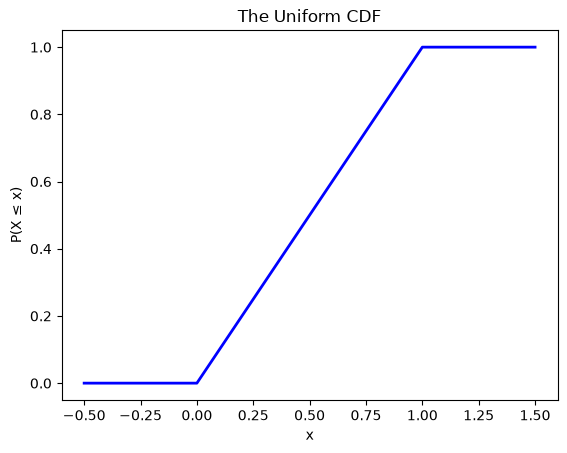

In [40]:
xs = [x / 100 for x in range(-50, 151)]
plt.plot(xs, [uniform_cdf(x) for x in xs], color='blue', linewidth=2)
plt.title("The Uniform CDF")
plt.xlabel("x")
plt.ylabel("P(X ≤ x)")
plt.show()

### Normal Distribution

The **normal distribution** is the king of distributions. It is the famous bell-shaped curve*. Many real things roughly follow it: heights of people, exam marks, measurement errors, weights of packets from a factory.

It is fully decided by just 2 numbers:
| Parameter | Symbol | Controls |
|---|---|---|
| Mean | $\mu$ (mu) | Where the centre of the bell is |
| Standard deviation | $\sigma$ (sigma) | How wide the bell is |

When $\mu$ = 0 and $\sigma$ = 1, it is called the **standard normal distribution**.

#### The pdf formula
$$f(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi}\,\sigma} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$



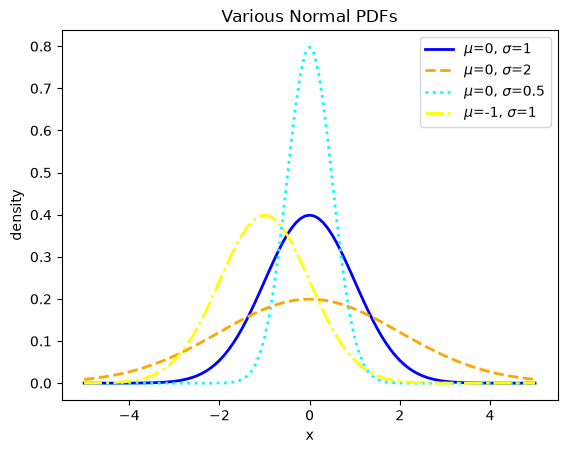

In [43]:
def normal_pdf(x, mu=0, sigma=1):
    sqrt_two_pi = math.sqrt(2 * math.pi)
    return math.exp(-(x - mu) ** 2 / 2 / sigma ** 2) / (sqrt_two_pi * sigma)

xs = [x / 10 for x in range(-50, 51)]
plt.plot(xs, [normal_pdf(x, sigma=1) for x in xs],   '-',  color='blue',   linewidth=2, label=r'$\mu$=0, $\sigma$=1')
plt.plot(xs, [normal_pdf(x, sigma=2) for x in xs],   '--', color='orange', linewidth=2, label= r'$\mu$=0, $\sigma$=2')
plt.plot(xs, [normal_pdf(x, sigma=0.5) for x in xs], ':',  color='aqua',   linewidth=2, label=r'$\mu$=0, $\sigma$=0.5')
plt.plot(xs, [normal_pdf(x, mu=-1) for x in xs],     '-.', color='yellow', linewidth=2, label=r'$\mu$=-1, $\sigma$=1')
plt.legend()
plt.title("Various Normal PDFs")
plt.xlabel("x")
plt.ylabel("density")
plt.show()

In [52]:
# Mean of the distribution 
Mean = np.array([-1, 0, 1, 1, 2])

# satndard deviation of the distribution
Standard_deviation  = np.array([0, 1, 0, 1, 2])
 
# size
size = 100000
 
# creating a normal distribution data
values = np.random.normal(loc=Mean, scale=Standard_deviation, size=(size, len(Mean)))

for i, (m, s) in enumerate(zip(Mean, Standard_deviation)):
    col = values[:, i]
    print(f"N({m}, {s}): sample mean = {col.mean():.4f}, sample std = {col.std():.4f}")

N(-1, 0): sample mean = -1.0000, sample std = 0.0000
N(0, 1): sample mean = -0.0008, sample std = 1.0019
N(1, 0): sample mean = 1.0000, sample std = 0.0000
N(1, 1): sample mean = 0.9967, sample std = 1.0000
N(2, 2): sample mean = 2.0095, sample std = 2.0009


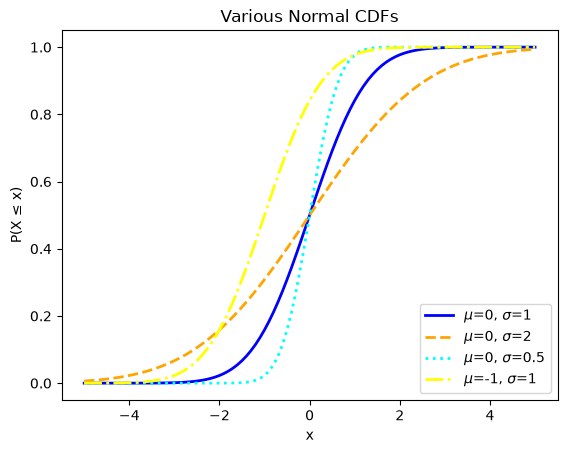

In [60]:
def normal_cdf(x, mu=0, sigma=1):
    return (1 + math.erf((x - mu) / math.sqrt(2) / sigma)) / 2

plt.plot(xs, [normal_cdf(x, sigma=1) for x in xs],   '-',  color='blue',   linewidth=2, label=r'$\mu$=0, $\sigma$=1')
plt.plot(xs, [normal_cdf(x, sigma=2) for x in xs],   '--', color='orange', linewidth=2, label= r'$\mu$=0, $\sigma$=2')
plt.plot(xs, [normal_cdf(x, sigma=0.5) for x in xs], ':',  color='aqua',   linewidth=2, label=r'$\mu$=0, $\sigma$=0.5')
plt.plot(xs, [normal_cdf(x, mu=-1) for x in xs],     '-.', color='yellow', linewidth=2, label=r'$\mu$=-1, $\sigma$=1')
plt.legend(loc="lower right")
plt.title("Various Normal CDFs")
plt.xlabel("x")
plt.ylabel("P(X ≤ x)")
plt.show()

In [61]:
mu, sigma = 165, 7

p_below_172 = normal_cdf(172, mu, sigma)
p_above_180 = 1 - normal_cdf(180, mu, sigma)
p_158_to_172 = normal_cdf(172, mu, sigma) - normal_cdf(158, mu, sigma)

print(f"P(height < 172 cm) = {p_below_172:.3f}")
print(f"P(height > 180 cm) = {p_above_180:.3f}")
print(f"P(158 cm < height < 172 cm) = {p_158_to_172:.3f}")

P(height < 172 cm) = 0.841
P(height > 180 cm) = 0.016
P(158 cm < height < 172 cm) = 0.683


In [62]:
def inverse_normal_cdf(p, mu=0, sigma=1, tolerance=0.00001):
    """Find the value x where normal_cdf(x) ≈ p, using binary search"""
    # if not standard normal, solve for standard and then rescale
    if mu != 0 or sigma != 1:
        return mu + sigma * inverse_normal_cdf(p, tolerance=tolerance)

    low_z, hi_z = -10.0, 10.0    # normal_cdf(-10) very close to 0, normal_cdf(10) very close to 1
    while hi_z - low_z > tolerance:
        mid_z = (low_z + hi_z) / 2  # try the middle point
        if normal_cdf(mid_z) < p:
            low_z = mid_z      # too low → search the upper half
        else:
            hi_z = mid_z       # too high → search the lower half
    return mid_z

# Exam marks: mean 60, standard deviation 10
cutoff = inverse_normal_cdf(0.90, mu=60, sigma=10)
print(f"To be in the top 10%, you need about {cutoff:.1f} marks")

To be in the top 10%, you need about 72.8 marks
